John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
library(ranger) # engine for random forest

# set random seed
set.seed(42)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() mask

Load data

In [2]:
data_list <- list()

# # TO RUN MODEL ON ALL 11 FOCAL MALES:
# folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id"
# files = list.files(folder_path, full.names=TRUE)

# for (file in files) {
#     data_list <- append(data_list, list(read_csv(file)))
# }

# TO RUN MODEL ON 1 FOCAL MALE:
file_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id\\YKY_song_type_id_frequency.csv" # TODO: Set file path to data for desired focal male
data_list <- append(data_list, list(read_csv(file_path)))

Rows: 1072 Columns: 139
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (1): ID
dbl  (137): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
focal_ids <- c()
for (i in seq_along(data_list)) {
    id <- data_list[[i]] %>% pull(ID) %>% unique()
    # print(id)
    focal_ids <- append(focal_ids, id)
}
# names(data_list) <- focal_ids
names(data_list) <- "YKY"

In [4]:
map(data_list, ~ head(.x, 3))

ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,n_ust_167,n_ust_168,n_ust_169,n_ust_170,n_ust_171,n_ust_172,n_ust_total,number_of_matches,does_it_match,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
YKY,16,2022-05-13 05:26:41,-1788.868,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,32,0,0,3
YKY,5,2022-05-13 05:26:47,-1782.303,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,1,0,0,3
YKY,13,2022-05-13 05:26:55,-1774.896,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,1,1,1,3


In [5]:
# In data (training AND testing), how many of each song type for the focal male?
for (i in seq_along(data_list)) {
    cat("All song types for", data_list[[i]] %>% pull(ID) %>% unique(), ':\n')
    n_ust <- data_list[[i]] %>%
        group_by(UST) %>%
        summarize(n = n()) %>%
        mutate(percent = 100*n/nrow(data_list[[i]])) %>%
        arrange(desc(percent))
    print(n_ust)
}


All song types for YKY :
# A tibble: 30 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1    21   100    9.33
 2     1    82    7.65
 3     9    82    7.65
 4   166    82    7.65
 5    27    78    7.28
 6     8    74    6.90
 7     3    69    6.44
 8    18    60    5.60
 9    19    58    5.41
10    16    51    4.76
# ℹ 20 more rows


In [6]:
# Set data types and select input columns
for (i in seq_along(data_list) ){
    focal_male_number <- data_list[[i]] %>% pull(male_number) %>% unique()
    data_list[[i]] <- data_list[[i]] %>% 
        mutate(across(contains("UST"), ~ as.factor(.x)),
            # across(contains("ust"), ~ as.integer(.x)), 
            does_it_match = as.factor(does_it_match),
            number_of_matches = as.integer(number_of_matches)) %>%
        select(
            # Response
            "UST",

            # All neighbours' songs since last own song
            contains("n_ust_"),

            # Own song history (song types)
            sprintf("M%i_1_last_UST", focal_male_number),
            sprintf("M%i_2_last_UST", focal_male_number),
            # sprintf("M%i_3_last_UST", focal_male_number),

            # Own song history (time since last songs)
            sprintf("time_since_M%i_1_last_song", focal_male_number),
            sprintf("time_since_M%i_2_last_song", focal_male_number),        
            # sprintf("time_since_M%i_3_last_song", focal_male_number)
        )  %>%
        drop_na() # drop any row containing at least one NA value
}


In [7]:
for (i in seq_along(data_list) ){
    print(focal_ids[i])
    cat("Columns:",length(data_list[[i]]), "Rows:", nrow(data_list[[i]]))
    print(glimpse(data_list[[i]]))
}

[1] "YKY"
Columns: 71 Rows: 1062Rows: 1,062
Columns: 71
$ UST                       <fct> 13, 10, 165, 17, 21, 166, 8, 3, 13, 21, 9, 2…
$ n_ust_1                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_3                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_4                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_5                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_6                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_7                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_8                   <fct> 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,…
$ n_ust_9                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_10                  <fct> 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0,…
$ n_ust_11                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,…
$ n_ust_12                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [8]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

In [9]:
models_list <- list()

for (i in seq_along(data_list)) {
    data <- data_list[[i]]
    # train test split
    train_test_split <- initial_split(data, prop = 0.7, strata=UST)

    train_data <- train_test_split %>% training()
    test_data <- train_test_split %>% testing()

    # In training data, how many of each song type?
    n_ust <- train_data %>%
        group_by(UST) %>%
        summarize(n = n()) %>%
        mutate(percent = 100*n/nrow(train_data)) %>%
        arrange(percent)
    n_ust

    # use v-fold cross validation to assess model accuracy
    v <- 5
    train_vfold <- vfold_cv(train_data, v=v, strata = UST)



    # Data preprocessing using a recipe
    recipe <- recipe(UST ~ ., data = train_data) %>%
        step_scale(all_numeric()) %>% # scale all numeric predictors
        step_center(all_numeric()) # center all numeric predictors


    model_tuning <- workflow() %>%
        add_recipe(recipe) %>%
        add_model(model_tuning_spec) %>%

            tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
            # fit(data = train_data) # to train on whole train set with no validation set

    model_tuning

    # Accuracies listed use 5-fold cross validation
    model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
    model_tuning_accuracies

    # plot accuracies of all values of hyperparameters

    ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
        geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
        geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
        labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
        theme(text = element_text(size=20)) +
        scale_fill_gradient(low="white", high="red")

    # Print best hyperparameter values
    best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
    print("Best hyperparameters: (mtry, min_n)")
    print(best_params)

    # retrain model on best parameters
    best_params <- model_tuning %>%
    select_best()
    print("Best Parameters:")
    print(best_params)

    model <- workflow() %>%
        add_recipe(recipe) %>%
        add_model(model_tuning_spec) %>%
        finalize_workflow(best_params) %>%
        # fit_resamples(resamples = train_vfold) # for v-fold cross validation
        fit(data = train_data) # to train on whole train set with no validation set

    models_list <- append(models_list, model)
}

Warning message:
"Too little data to stratify.
• Resampling will be unstratified."
Warning message:
"Too little data to stratify.
• Resampling will be unstratified."
→ A | warning: Dropped unused factor level(s) in dependent variable: 29, 36, 168, 171.

There were issues with some computations   A: x1

There were issues with some computations   A: x3

There were issues with some computations   A: x10

There were issues with some computations   A: x21

There were issues with some computations   A: x36

There were issues with some computations   A: x55

There were issues with some computations   A: x66

There were issues with some computations   A: x78

There were issues with some computations   A: x91

There were issues with some computations   A: x120

There were issues with some computations   A: x136

There were issues with some computations   A: x153

There were issues with some computations   A: x190

There were issues with some computations   A: x231

There were issues with some c

[1] "Best hyperparameters: (mtry, min_n)"
20 
20 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    20    20 pre0_mod25_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 29, 171."


In [16]:
train_data

UST,n_ust_1,n_ust_3,n_ust_4,n_ust_5,n_ust_6,n_ust_7,n_ust_8,n_ust_9,n_ust_10,⋯,n_ust_168,n_ust_169,n_ust_170,n_ust_171,n_ust_172,n_ust_total,M3_1_last_UST,M3_2_last_UST,time_since_M3_1_last_song,time_since_M3_2_last_song
<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>
13,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,1,5,16,7.406662,13.971596
10,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,2,13,5,8.165534,15.572196
165,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,1,10,13,7.268796,15.434330
17,0,0,0,0,0,0,1,0,0,⋯,0,0,0,0,0,1,165,10,6.355644,13.624440
3,0,0,0,0,0,0,0,0,1,⋯,0,0,0,0,0,1,8,166,6.730904,12.168727
13,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,3,8,5.525884,12.256788
21,0,0,0,0,0,0,0,0,1,⋯,0,0,0,0,0,2,13,3,6.722395,12.248279
9,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,1,21,13,7.109561,13.831956
21,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,1,9,21,6.628381,13.737942


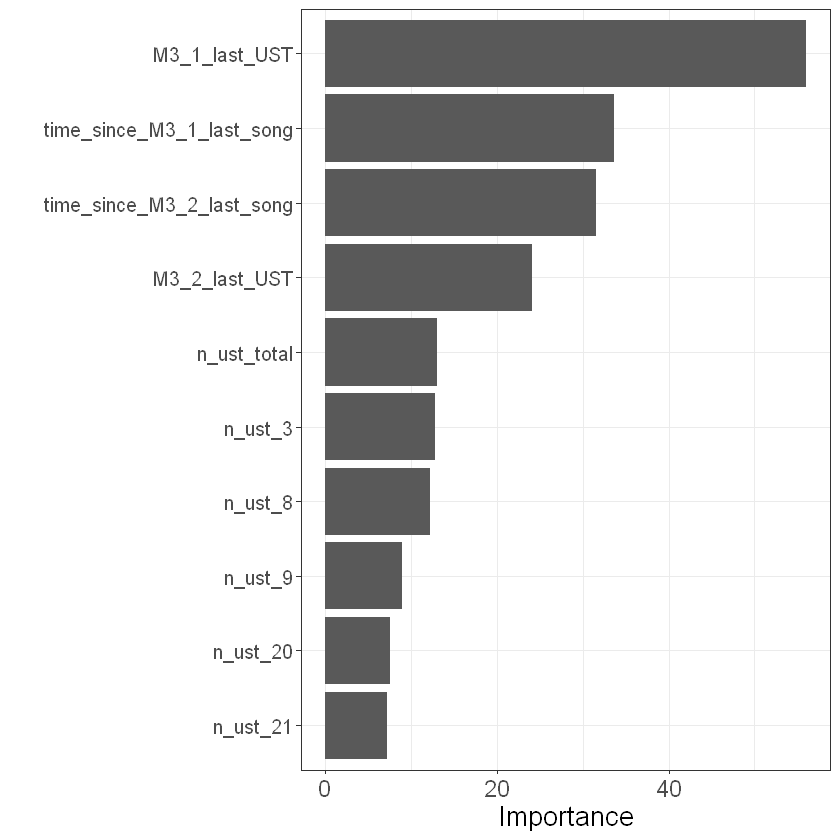

In [10]:
model %>% extract_fit_engine() %>% vip(num_features=10) +
  theme_bw() + # Starting with a clean theme
  theme(
    axis.text.x = element_text(size = 14),       # X-axis tick labels
    axis.text.y = element_text(size = 12),       # Y-axis tick labels
    axis.title.x = element_text(size = 16),      # X-axis title
    axis.title.y = element_text(size = 16),      # Y-axis title
    plot.title = element_text(size = 18, face = "bold"), # Main plot title
    legend.text = element_text(size = 12),       # Legend labels
    legend.title = element_text(size = 14)       # Legend title
  )

In [11]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [12]:
# test_predictions

In [13]:
# What was the accuracy, precision, and recall of our model?
test_accuracy <- test_predictions %>% metrics(truth = UST, estimate = .pred_class) %>% filter(.metric == "accuracy")
test_accuracy

test_predictions %>% group_by(UST) %>% metrics(truth = UST, estimate = .pred_class) %>% filter(.metric == "accuracy") %>% arrange(desc(.estimate)) %>% 
    select(UST, .estimate) %>% rename(estimated_accuracy = .estimate) %>%
    left_join(n_ust %>% select(UST, n), by = "UST") 

test_predictions %>% group_by(UST) %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate)) # Precision = correct positive predictions / total positive predictions
test_predictions %>% group_by(UST) %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate)) # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.2852665


UST,estimated_accuracy,n
<fct>,<dbl>,<int>
35,0.75000000,24
9,0.55000000,62
1,0.51851852,54
166,0.44000000,56
27,0.43478261,55
5,0.42857143,22
10,0.40000000,37
8,0.37500000,50
21,0.37142857,64


Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 2, '1': 0, '3': 0, '5': 0, '9': 0, '10': 0, '12': 0, '13': 0, '16': 0,
'17': 0, '18': 0, '19': 0, '20': 0, '21': 0, '22': 0, '26': 0, '29': 0, '30':
0, '35': 0, '36': 0, '165': 0, '166': 0, '167': 0, '168': 0, '169': 0, '170':
0, '171': 0, '172': 0"
Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 0, '3': 0, '5': 0, '8': 0, '9': 0, '12': 0, '13': 0, '17': 0, '20': 0,

UST,.metric,.estimator,.estimate
<fct>,<chr>,<chr>,<dbl>
35,precision,macro,0.50000000
167,precision,macro,0.25000000
5,precision,macro,0.20000000
9,precision,macro,0.20000000
10,precision,macro,0.20000000
16,precision,macro,0.20000000
169,precision,macro,0.16666667
3,precision,macro,0.14285714
1,precision,macro,0.12500000


Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'1': 0, '3': 0, '5': 0, '8': 1, '9': 0, '10': 0, '12': 0, '13': 0, '16': 0,
'17': 0, '18': 0, '19': 0, '20': 0, '21': 0, '22': 0, '26': 0, '27': 1, '29':
0, '30': 0, '35': 0, '36': 0, '165': 0, '166': 0, '167': 0, '168': 0, '169': 0,
'170': 0, '171': 0, '172': 0"
Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'0': 0, '3': 0, '5': 0, '8': 0, '9': 0, '10': 1, '12': 0, '13': 0, '16': 1,
'1

UST,.metric,.estimator,.estimate
<fct>,<chr>,<chr>,<dbl>
35,recall,macro,0.75000000
9,recall,macro,0.55000000
1,recall,macro,0.51851852
166,recall,macro,0.44000000
27,recall,macro,0.43478261
5,recall,macro,0.42857143
10,recall,macro,0.40000000
8,recall,macro,0.37500000
21,recall,macro,0.37142857


In [14]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  1  3  5  8  9 10 12 13 16 17 18 19 20 21 22 26 27 29 30 35 36
       0    0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
       1    0 14  2  0  0  0  0  0  2  0  1  5  4  0  4  0  0  2  0  0  0  0
       3    0  0  1  0  2  0  0  0  0  0  0  0  0  0  3  0  0  0  1  0  0  0
       5    0  0  0  3  1  0  0  0  2  0  0  1  0  0  1  0  0  0  0  0  0  0
       8    1  0  6  0  9  3  0  0  0  0  0  2  0  1  3  0  0  1  0  0  0  0
       9    0  0  6  1  3 11  0  0  0  1  0  1  2  1  0  0  0  2  0  0  0  1
       10   0  1  0  0  0  0  4  0  1  4  0  1  1  0  1  0  0  1  0  0  0  0
       12   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
       13   0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0
       16   0  1  0  0  0  1  2  0  3  3  0  0  0  2  2  0  0  0  0  0  0  0
       17   0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0
       18   0  1  0  1  0  0  1  0  0  0  0  2  1  0  2  0  